In [31]:
import os
import zipfile
from collections import Counter
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from google.colab import drive, files
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# 1. 드라이브 마운트 & 압축 해제
drive.mount('/content/drive/')

zip_path = '/content/drive/MyDrive/오즈코딩/13_해커톤/open.zip'
data_dir = '/content/chest_xray'

with zipfile.ZipFile(zip_path, 'r') as zf:
    zf.extractall(data_dir)

Mounted at /content/drive/


In [4]:
# 2. CSV 로드
train_df = pd.read_csv(f'{data_dir}/train.csv')
test_df = pd.read_csv(f'{data_dir}/test.csv')
sample_submission = pd.read_csv(f'{data_dir}/sample_submission.csv')

In [5]:
# 3. CSV ↔ 실제 이미지 파일명 일치 확인
for name, df in [('train', train_df), ('test', test_df)]:
    files = set(os.listdir(f'{data_dir}/{name}'))
    print(f'{name}: CSV {len(df)}행 / 이미지 {len(files)}장 / 파일명 일치 {set(df["file_name"]) == files}')

train: CSV 5216행 / 이미지 5216장 / 파일명 일치 True
test: CSV 624행 / 이미지 624장 / 파일명 일치 True


In [6]:
# 4. 클래스 분포 (개수 + 비율)
dist = train_df['label'].value_counts().sort_index()
print(pd.DataFrame({'count': dist, 'ratio(%)': (dist / dist.sum() * 100).round(2)}))

       count  ratio(%)
label                 
0       1341     25.71
1       3875     74.29


In [7]:
# 5. Train / Validation 분할 (label 비율 유지)
train_split, val_split = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    stratify=train_df['label']
)
print(f'Train: {len(train_split)} / Validation: {len(val_split)} / Test: {len(test_df)}')

Train: 4172 / Validation: 1044 / Test: 624


In [10]:
# @title
# GPU 사용 여부 확인
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

# 사전 학습된 ResNet18 불러오기
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# 마지막 분류층을 정상 / 폐렴 2개 클래스로 변경
model.fc = nn.Linear(model.fc.in_features, 2)

# GPU 또는 CPU로 모델 이동
model = model.to(device)

print("사용 장치:", device)
print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s]


사용 장치: cuda
Linear(in_features=512, out_features=2, bias=True)


## ResNet 18


In [16]:
# ResNet18을 학습하기 위한 기본 이미지 전처리

# 학습 데이터용: 데이터 증강 적용
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(7),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 검증 데이터용: 데이터 증강 없이 전처리
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 데이터셋 클래스
class ChestXrayDataset(Dataset):
    def __init__(self, df, image_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_path = os.path.join(
            self.image_dir, row['file_name']
        )

        image = Image.open(image_path).convert('L')

        if self.transform:
            image = self.transform(image)

        if 'label' in self.df.columns:
            label = int(row['label'])
            return image, label

        return image

# 데이터셋 생성
train_dataset = ChestXrayDataset(
    train_split, '/content/chest_xray/train', train_transform
)

val_dataset = ChestXrayDataset(
    val_split, '/content/chest_xray/train', val_transform
)

# DataLoader 생성
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

# 입력 형태 확인
images, labels = next(iter(train_loader))

print("이미지 형태:", images.shape)
print("레이블 형태:", labels.shape)

이미지 형태: torch.Size([32, 3, 224, 224])
레이블 형태: torch.Size([32])


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. 손실 함수와 옵티마이저
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# 2. 학습 설정
num_epochs = 5

for epoch in range(num_epochs):

    # 학습 단계
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)

        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    # 검증 단계
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)

            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    # 결과 출력
    train_loss /= train_total
    val_loss /= val_total

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch [1/5] Train Loss: 0.0222, Train Acc: 0.9921, Val Loss: 0.0817, Val Acc: 0.9732
Epoch [2/5] Train Loss: 0.0117, Train Acc: 0.9957, Val Loss: 0.0305, Val Acc: 0.9904
Epoch [3/5] Train Loss: 0.0082, Train Acc: 0.9969, Val Loss: 0.0331, Val Acc: 0.9885
Epoch [4/5] Train Loss: 0.0067, Train Acc: 0.9974, Val Loss: 0.0334, Val Acc: 0.9895
Epoch [5/5] Train Loss: 0.0032, Train Acc: 0.9990, Val Loss: 0.0431, Val Acc: 0.9895


## DenseNet121

In [18]:
# DenseNet121 모델 생성
model_dense = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

# 마지막 분류층 변경
model_dense.classifier = nn.Linear(
    model_dense.classifier.in_features, 2
)

# GPU 또는 CPU에 모델 올리기
model_dense = model_dense.to(device)

# 손실 함수
criterion_dense = nn.CrossEntropyLoss()

# 옵티마이저
optimizer_dense = optim.Adam(
    model_dense.parameters(),
    lr=0.0001
)

# 학습 횟수
num_epochs_dense = 5

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 152MB/s]


In [21]:
# DenseNet121 모델 새로 생성 (기존 학습 초기화)
model_dense = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

model_dense.classifier = nn.Linear(
    model_dense.classifier.in_features, 2
)

model_dense = model_dense.to(device)

# 옵티마이저도 새로 생성
optimizer_dense = optim.Adam(
    model_dense.parameters(),
    lr=0.0001
)

# 손실 함수
criterion_dense = nn.CrossEntropyLoss()

# Epoch 설정
num_epochs_dense = 5

In [22]:
# 최고 성능 모델 저장을 위한 변수
best_val_acc = 0.0
best_model_state = None
best_epoch = 0

for epoch in range(num_epochs_dense):

    # 학습 단계
    model_dense.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_dense.zero_grad()

        outputs = model_dense(images)
        loss = criterion_dense(outputs, labels)

        loss.backward()
        optimizer_dense.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)

        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # 검증 단계
    model_dense.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_dense(images)
            loss = criterion_dense(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)

            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{num_epochs_dense}] "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc:.4f}"
    )

    # 검증 정확도가 가장 높을 때 모델 저장
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model_dense.state_dict().items()
            }

    print(f"현재 최고 검증 정확도: {best_val_acc:.4f}")

print(f"최고 성능 Epoch: {best_epoch}")
print(f"최고 검증 정확도: {best_val_acc:.4f}")

Epoch [1/5] Train Loss: 0.1187, Train Acc: 0.9559, Val Loss: 0.0567, Val Acc: 0.9770
현재 최고 검증 정확도: 0.9770
Epoch [2/5] Train Loss: 0.0462, Train Acc: 0.9856, Val Loss: 0.0407, Val Acc: 0.9847
현재 최고 검증 정확도: 0.9847
Epoch [3/5] Train Loss: 0.0383, Train Acc: 0.9854, Val Loss: 0.0378, Val Acc: 0.9866
현재 최고 검증 정확도: 0.9866
Epoch [4/5] Train Loss: 0.0227, Train Acc: 0.9923, Val Loss: 0.0645, Val Acc: 0.9789
현재 최고 검증 정확도: 0.9866
Epoch [5/5] Train Loss: 0.0161, Train Acc: 0.9938, Val Loss: 0.0590, Val Acc: 0.9818
현재 최고 검증 정확도: 0.9866
최고 성능 Epoch: 3
최고 검증 정확도: 0.9866


## 혼동 행렬 검사 및 최적 모델 선정

혼동행렬:
[[266   2]
 [ 19 757]]


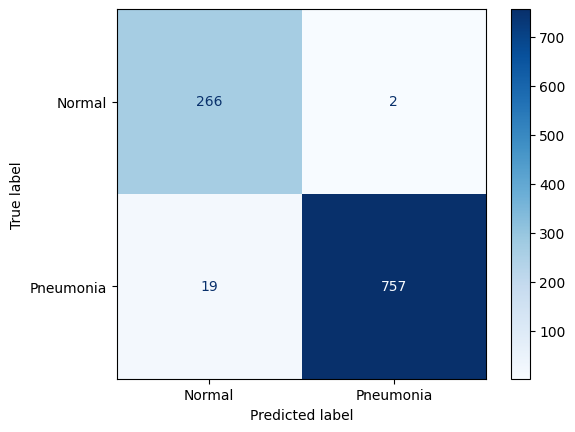

In [20]:
# @title
# 검증 데이터 예측
model_dense.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model_dense(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# 혼동행렬 계산
cm = confusion_matrix(y_true, y_pred)

print("혼동행렬:")
print(cm)

# 혼동행렬 시각화
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

display.plot(cmap="Blues", values_format="d")
plt.show()

In [23]:
# 최적 모델 불러오기
model_dense.load_state_dict(best_model_state)
model_dense = model_dense.to(device)

In [26]:
model_dense.eval()

all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model_dense(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

print("예측 확률 개수:", len(all_probs))
print("실제 라벨 개수:", len(all_labels))

예측 확률 개수: 1044
실제 라벨 개수: 1044


In [29]:
# 판정 기준 조절
for threshold in [0.4, 0.3, 0.2]:
    preds = (all_probs >= threshold).astype(int)

    print(f"\n판정 기준: {threshold}")
    print("혼동 행렬:")
    print(confusion_matrix(all_labels, preds))

    print("\n분류 보고서:")
    print(classification_report(
        all_labels,
        preds,
        target_names=["Normal", "Pneumonia"],
        digits=4
    ))


판정 기준: 0.4
혼동 행렬:
[[266   2]
 [ 11 765]]

분류 보고서:
              precision    recall  f1-score   support

      Normal     0.9603    0.9925    0.9761       268
   Pneumonia     0.9974    0.9858    0.9916       776

    accuracy                         0.9875      1044
   macro avg     0.9788    0.9892    0.9839      1044
weighted avg     0.9879    0.9875    0.9876      1044


판정 기준: 0.3
혼동 행렬:
[[266   2]
 [ 10 766]]

분류 보고서:
              precision    recall  f1-score   support

      Normal     0.9638    0.9925    0.9779       268
   Pneumonia     0.9974    0.9871    0.9922       776

    accuracy                         0.9885      1044
   macro avg     0.9806    0.9898    0.9851      1044
weighted avg     0.9888    0.9885    0.9886      1044


판정 기준: 0.2
혼동 행렬:
[[263   5]
 [  8 768]]

분류 보고서:
              precision    recall  f1-score   support

      Normal     0.9705    0.9813    0.9759       268
   Pneumonia     0.9935    0.9897    0.9916       776

    accuracy                 

In [32]:
# 테스트 데이터셋과 데이터 로더 만들기
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = ChestXrayDataset(
    test_df,
    '/content/chest_xray/test',
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [33]:
# 테스트 데이터에서 DesNet121모델 적용해 예측 확률 구하고 판정 기준 0.3 적용
model_dense.eval()

test_preds = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)

        outputs = model_dense(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]

        preds = (probs >= 0.3).long()
        test_preds.extend(preds.cpu().numpy())

print("테스트 이미지 수:", len(test_preds))
print("정상 예측:", test_preds.count(0))
print("폐렴 예측:", test_preds.count(1))

테스트 이미지 수: 624
정상 예측: 254
폐렴 예측: 370


In [34]:
# csv 파일 저장
submission = pd.read_csv(f'{data_dir}/sample_submission.csv')

submission['label'] = test_preds

submission.to_csv(
    f'{data_dir}/submission_densenet121_threshold03.csv',
    index=False
)

print(submission.head())
print("제출 파일 저장 완료!")

       file_name  label
0  test_0001.png      0
1  test_0002.png      0
2  test_0003.png      1
3  test_0004.png      1
4  test_0005.png      1
제출 파일 저장 완료!


In [35]:
print(data_dir)

/content/chest_xray
